# SQUID JPA (twpa-sim `squid_jpa`), flux-pumped, rebuilt in the Quantcore PDK

**What it is.** A lumped JPA whose inductor is a DC SQUID: the static flux tunes the mode, and a pump on the flux
line at twice the signal frequency modulates the SQUID inductance — three-wave mixing, phase-preserving gain in
reflection, with the pump far from the signal band (Yamamoto et al. 2008; Roy & Devoret 2016).

**Source.** twpa-sim (S. Mandal, MIT), `src/twpa/layout/generate.py`, family `squid_jpa`
(`examples/layout/squid_jpa.json`: two 2 µm junctions in a loop, branch height 20 µm, a 12 × 12 µm MIM shunt) on
its illustrative process (I_c 20 µA and C_J 240 fF per junction, 144 fF MIM). twpa-sim leaves the coupling and the
flux line external. Read-only clone `build/external/twpa-sim` (rev 05abc83), never run.

| | twpa-sim source | Quantcore rebuild (why) |
|---|---|---|
| SQUID | two 2 × 2 µm overlap JJs (40 µA total), loop 20 µm high | the **largest PDK trilayer SQUID** (two 2 × 2 µm fingers, I_c,tot 1.3 µA, L_s(0) 0.25 nH), junctions ±8 µm apart; flagged `pdk_rn` |
| shunt C | MIM 144 fF | interdigital island–ground capacitor ≈ 1.6 pF (f0 ≈ 7 GHz with the PDK SQUID) |
| coupling, flux | external | KQC `FingerCapacitorSquare` snapped to the island lead; a shorted flux / pump CPW past the SQUID's ground side (`flux_line`, 2 µm ground strip, as QPDK's pump) |
| f0 | ≈ 70 GHz with the illustrative values | ≈ 7 GHz |
| chip | none | 7.5 × 7.5 mm PDK die, signal and flux `BondPad`s 100 µm from the edge |

## 1 · Setup and the PDK

In [2]:
import os, sys
from pathlib import Path
import numpy as np
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "examples" / "designs"))
sys.path.insert(0, str(ROOT / "examples" / "designs" / "amplifiers"))
from _common import *
from _amplifiers import pdk_facts_md, plot, show_md, table_md
from quantcore_circuits.designer import Designer
from quantcore_circuits.pdk import get_pdk
from quantcore_circuits.analysis import amplifiers as amp
from quantcore_circuits.layouts.others.amplifiers import LumpedJpa, drawn_junction_values
from quantcore_circuits.circuit.bridges import rn_from_lj

LIVE = os.environ.get("QCC_LIVE", "1") == "1"
RUN_FEM = False
OUT = Path("examples/designs/amplifiers")
PDK = get_pdk()
show_md(pdk_facts_md(PDK))

| PDK | value |
|---|---|
| substrate | sapphire 650 µm, εr 10.25 |
| film | Nb 200 nm, λ_L 90 nm → L_s 0.116 pH/□ (kinetic, in every CPW / wire formula) |
| junction rule | Nb/AlOx/Nb trilayer, Δ 1.4 meV, J_c 0.163 µA/µm², R_n window 40–50 kΩ, fingers 0.1–2 µm |
| frame | die 7.5 × 7.5 mm standard, margin 100 µm, marker areas 500 µm, brand QCT |
| pad rule | outer etch 100 µm (one dicing-marker width) from the die edge (`edge="auto"`) |
| cheese | PDK band 3 rows of 5 µm squares, 20 µm gap, around the 3/0 keep-outs (unless the original has its own) |
| 3/0 keep-out | routes + 10 µm, components + 24 µm |

In [3]:
BIG_JJ = {"finger_width": 2.0, "second_finger_width": 2.0}
LS0, CJ, _ = drawn_junction_values("Quantcore Squid", BIG_JJ)
JUNCTION = {"Lj_nH": LS0, "Cj_fF": CJ}
ls_src = amp.lj_from_ic(40e-6) * 1e9
f_src = 1 / (2 * np.pi * np.sqrt(ls_src * 1e-9 * (480 + 144) * 1e-15)) / 1e9
show_md(table_md(["SQUID", "I_c,tot (µA)", "L_s(0) (nH)", "C_J (fF)", "device R_n (kΩ)"], [
    ["drawn: 2 × trilayer 2.0 × 2.0 µm", amp.ic_from_lj(LS0 * 1e-9) * 1e6, LS0, CJ, rn_from_lj(LS0) / 1e3],
    ["twpa-sim illustrative", 40.0, ls_src, 480.0, rn_from_lj(ls_src) / 1e3]])
    + f"\n\ntwpa-sim's own values: f0 ≈ {f_src:.0f} GHz (illustrative).")

| SQUID | I_c,tot (µA) | L_s(0) (nH) | C_J (fF) | device R_n (kΩ) |
|---|---|---|---|---|
| drawn: 2 × trilayer 2.0 × 2.0 µm | 1.303 | 0.2525 | 400 | 1.687 |
| twpa-sim illustrative | 40 | 0.008228 | 480 | 0.05498 |

twpa-sim's own values: f0 ≈ 70 GHz (illustrative).

## 2 · The die and frame

In [4]:
W = H = 7500
YC = 3750
d = Designer("twpa_sim_squid_jpa", box=(0, 0, W, H), chip={"name_chip": "SQJPA"}, live=LIVE)

## 3 · Pads (the 100 µm rule)
The signal pad on the west edge, the flux / pump pad on the east edge, both `edge="auto"`.

In [5]:
with d.batch():
    d.add("P_SIG", "BondPad", at=(400, YC), rot=-90, edge="auto")
    d.add("P_FLUX", "BondPad", at=(7100, YC - 500), rot=90, edge="auto")

## 4 · Components
`JS` (`LumpedJpa`, `junction_type="Quantcore Squid"`, `flux_line=True`): the island IDC (45 fingers per side,
180 µm), the trilayer SQUID across the 16 µm gap at the far end (its straight fingers on the island's landing head,
its bent fingers on the 2 µm ground strip), the shorted flux CPW beyond it. `CC`: the coupling capacitor, snapped
to the island lead. `flux_phi0` is the static bias the LOM uses (Φ0).

In [6]:
SHUNT = dict(shunt_fingers=45, finger_length=180, finger_width=4, finger_gap=4)
with d.batch():
    d.add("CC", "FingerCapacitorSquare", at=(2700, YC), finger_number=14, finger_length=90, finger_width=5,
          finger_gap=3)
    js = d.add("JS", "LumpedJpa", snap="signal", to="CC.b", junction_type="Quantcore Squid", flux_line=True,
               junction=JUNCTION, junction_params=BIG_JJ, **SHUNT)
show_md(f"C_shunt ≈ {LumpedJpa.qcc_values(js.spec['params'])['C_shunt_fF']:.0f} fF (analytic IDC)")

C_shunt ≈ 1590 fF (analytic IDC)

## 5 · Routes
The 50 Ω feed `L_SIG`; the flux line `L_FLUX` from the SQUID's flux port (facing south) to the east pad — it
carries the static bias and the pump at 2 f0.

In [7]:
with d.batch():
    d.route("L_SIG", "P_SIG.a", "CC.a")
    xf, yf = port_xy(d, "JS.flux")
    d.route("L_FLUX", "JS.flux", "P_FLUX.a", nodes=[(xf, YC - 500)], r=80)
d.sim_group("jpa", ["CC", "JS"], margin_um=100, analyses=["q3d_cmatrix", "eigenmode_epr"])
if not LIVE:
    d.show()
DESIGN = d.save(OUT / "twpa_sim_squid_jpa.json")
print(d, "→", DESIGN)

<Designer twpa_sim_squid_jpa: 4 instances, 2 routes, live=False> → examples\designs\amplifiers\twpa_sim_squid_jpa.json


## 6 · DRC
`pdk_rn` flags the SQUID's device R_n (≈ 1.7 kΩ against the qubit window): an amplifier SQUID, as designed.

In [8]:
print(d.drc())
show_md(pdk_report(d))

warning dangling_port JS.squid_a is not connected (no route or snap)
warning dangling_port JS.squid_b is not connected (no route or snap)
design  pdk_rn        JS: junction R_n 1.7 kΩ is outside the PDK window 40–50 kΩ (L_J 0.25254 nH)


| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (+0, -250) µm |
| junction types | Quantcore Squid × 1 |
| PDK design warnings | 1 (pdk_rn × 1) |
| pdk_rn | JS: junction R_n 1.7 kΩ is outside the PDK window 40–50 kΩ (L_J 0.25254 nH) |

## 7 · Netlist and LOM
The island node carries C_shunt and the `SQUID` branch (L_s0, C_J, `flux_phi0`); `CC` couples it to the pad node;
the flux line is a control (`flux_bias` on `J_JS`), no circuit element.

In [9]:
lb = d.lom()
show_netlist(lb)

**3 nodes · 6 branches · 1 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `CC.a` | `P_SIG.pad`, `CC.a` |
| `JS` | `CC.b`, `JS.island` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_P_SIG` | R | `CC.a` – `gnd` | 50 Ω |
| `C_CC` | C | `CC.a` – `JS` | 77.3 fF |
| `C_CC_a` | C | `CC.a` – `gnd` | 14 fF |
| `C_CC_b` | C | `JS` – `gnd` | 14 fF |
| `C_JS` | C | `JS` – `gnd` | 1.59e+03 fF |
| `J_JS` | SQUID | `JS` – `gnd` | Lj 0.253 nH, Cj 400 fF |

| control | kind | target | line | length (µm) |
|---|---|---|---|---|
| `L_FLUX` | flux_bias | `J_JS` | `L_FLUX` | 2970 |

**Unconnected ports:** none

**Builder notes:**

- JS: lumped JPA, C_shunt ≈ 1590 fF (analytic IDC)
- Port_P_FLUX: both ends on gnd after merging conductors (dropped)

## 8 · LOM simulation: tuning, Q, gain
**(a)** QuCat modes at zero flux, then the static flux bias swept through `flux_phi0` (each point a LOM rebuild).

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| JS | qubit | 6.9461 | 42 | 9.3 | J_JS 1.00 |

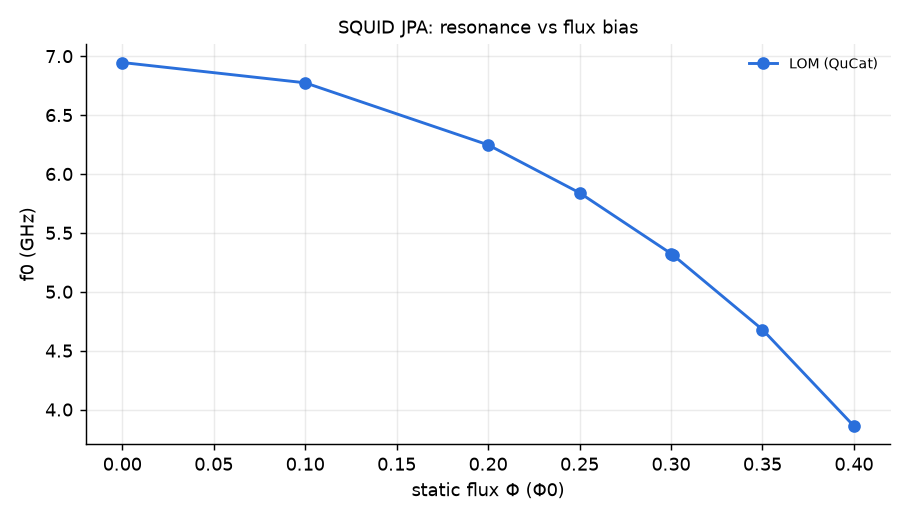

| Φ (Φ0) | f0 (GHz) | κ/2π (MHz) | Q_ext | |K|/2π (MHz) |
|---|---|---|---|---|
| 0 | 6.946 | 41.95 | 165.6 | 9.34 |
| 0.1 | 6.774 | 39.97 | 169.5 | 9.338 |
| 0.2 | 6.247 | 34.17 | 182.8 | 9.334 |
| 0.25 | 5.84 | 29.97 | 194.9 | 9.33 |
| 0.3 | 5.324 | 25.02 | 212.8 | 9.327 |
| 0.35 | 4.679 | 19.42 | 241 | 9.322 |
| 0.4 | 3.86 | 13.28 | 290.6 | 9.317 |

In [10]:
sel = {"jpa": ["P_SIG", "L_SIG", "CC", "JS"]}
res0 = simulate_groups(d, sel, max_modes=1)["jpa"]
display(Markdown(modes_md(res0)))
PHIS = [0.0, 0.1, 0.2, 0.25, 0.3, 0.301, 0.35, 0.4]
tune = {}
for phi in PHIS:
    d["JS"].set(flux_phi0=phi)
    tune[phi] = simulate_groups(d, sel, max_modes=1)["jpa"].modes[0]
d["JS"].set(flux_phi0=0.0)
plot(OUT / "twpa_sim_squid_jpa_tuning.png", [([p for p in PHIS], [tune[p].f_GHz for p in PHIS], "LOM (QuCat)", "o-")],
     "static flux Φ (Φ0)", "f0 (GHz)", "SQUID JPA: resonance vs flux bias")
show_md(table_md(["Φ (Φ0)", "f0 (GHz)", "κ/2π (MHz)", "Q_ext", "|K|/2π (MHz)"],
                 [[p, m.f_GHz, m.kappa_MHz, m.f_GHz * 1e3 / m.kappa_MHz, abs(m.anharmonicity_MHz)]
                  for p, m in tune.items() if p != 0.301]))

**(b) Flux-pumped gain** at Φ = 0.3 Φ0 (single-mode model): δω = 2π |df0/dΦ| Φ_p, r = δω/κ.

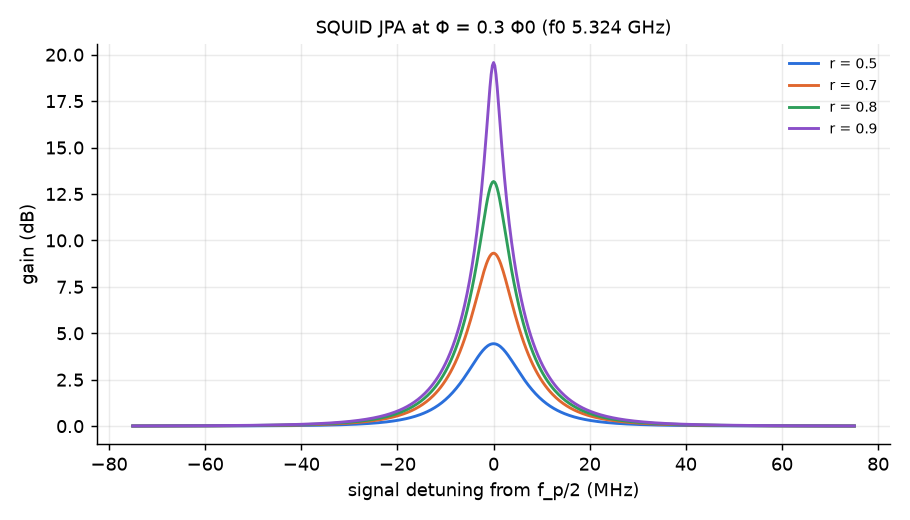

| r | peak gain (dB) | pump flux Φ_p (mΦ0) |
|---|---|---|
| 0.5 | 4.437 | 1.084 |
| 0.7 | 9.312 | 1.517 |
| 0.8 | 13.17 | 1.734 |
| 0.9 | 19.58 | 1.951 |

df0/dΦ = -11.54 GHz/Φ0, κ/2π = 25.0 MHz

In [11]:
op = tune[0.3]
df_dphi = (tune[0.301].f_GHz - op.f_GHz) * 1e9 / 1e-3        # Hz / Φ0
kappa = op.kappa_MHz * 1e6
det = np.linspace(-3, 3, 601) * kappa
plot(OUT / "twpa_sim_squid_jpa_gain.png",
     [(det / 1e6, amp.db(amp.flux_pumped_gain(det, kappa, r)), f"r = {r}") for r in (0.5, 0.7, 0.8, 0.9)],
     "signal detuning from f_p/2 (MHz)", "gain (dB)", f"SQUID JPA at Φ = 0.3 Φ0 (f0 {op.f_GHz:.3f} GHz)")
show_md(table_md(["r", "peak gain (dB)", "pump flux Φ_p (mΦ0)"],
                 [[r, float(amp.db(amp.flux_pumped_peak_gain(r))), 1e3 * r * kappa / abs(df_dphi)]
                  for r in (0.5, 0.7, 0.8, 0.9)]) + f"\n\ndf0/dΦ = {df_dphi / 1e9:.2f} GHz/Φ0, κ/2π = {kappa / 1e6:.1f} MHz")

## 9 · FEM: send the jobs
Q3D C-matrix of capacitor + island, eigenmode with the SQUID as a lumped inductor (export only). The flux line's
mutual inductance to the SQUID loop needs a magnetostatic / driven run (not exported).

In [12]:
jobs = export_sims(DESIGN, ["jpa"])
jobs_eig = export_sims(DESIGN, ["jpa"], analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))
if RUN_FEM:
    from quantcore_circuits.sim_tools import solve_job
    for job, _ in list(jobs.values()) + list(jobs_eig.values()):
        solve_job(job)

| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| jpa | `build/jobs/twpa_sim_squid_jpa_jpa_q3d_cmatrix` | 1 · junction · `JS.junction`<br>2 · edge · `L_FLUX`<br>3 · edge · `L_SIG` | `JS.island`, `L_SIG` |
| jpa | `build/jobs/twpa_sim_squid_jpa_jpa_eigenmode_epr` | 1 · junction · `JS.junction`<br>2 · edge_lumped · `L_FLUX`<br>3 · edge_lumped · `L_SIG` | `JS.island`, `L_FLUX`, `L_SIG` |

## 10 · Bring it back

In [13]:
job = jobs["jpa"][0]
show_md("C-matrix found: `fill(lb.model, d.design, job)` then re-run section 8" if (Path(job) / "results" /
        "results.json").exists() else f"No results in `{job}` yet: the IDC and coupling C are analytic estimates.")

No results in `build\jobs\twpa_sim_squid_jpa_jpa_q3d_cmatrix` yet: the IDC and coupling C are analytic estimates.

## 11 · Iterate: the coupling capacitor
One property: 14 → 8 coupling fingers (smaller C_c: higher Q, narrower band, lower pump threshold).

In [14]:
d["CC"].set(finger_number=8)
m8 = simulate_groups(d, sel, max_modes=1)["jpa"].modes[0]
d["CC"].set(finger_number=14)
show_md(table_md(["coupling fingers", "f0 (GHz)", "κ/2π (MHz)", "Q_ext"],
                 [[14, res0.modes[0].f_GHz, res0.modes[0].kappa_MHz, res0.modes[0].f_GHz * 1e3 / res0.modes[0].kappa_MHz],
                  [8, m8.f_GHz, m8.kappa_MHz, m8.f_GHz * 1e3 / m8.kappa_MHz]]))
DESIGN = d.save(OUT / "twpa_sim_squid_jpa.json")

| coupling fingers | f0 (GHz) | κ/2π (MHz) | Q_ext |
|---|---|---|---|
| 14 | 6.946 | 41.95 | 165.6 |
| 8 | 7.009 | 13.67 | 512.9 |

## 12 · Build and export
`qcc build` / `qcc mask` on `examples/designs/amplifiers/twpa_sim_squid_jpa.json`.

In [15]:
from quantcore_circuits.layouts.wafers.fab_export import export_fab
if d.result is None:
    d.show()
fab = {}
export_fab(d.result, Path("build") / f"{d.design.name}_fab.oas", report=fab)
show_md(f"cheese: {fab.get('cheese_source')}; written: " + ", ".join(f"{k} {n}" for k, n in fab["written"].items()))

cheese: build; written: M1 2143, JJ_STRAIGHT 1, M3 2141, JJ_BENT 3, HSQ 4, SPACER_1 4, SPACER_2 4, SPACER_3 4, CHIP_BOUNDARY 1, MARKERS_DICING 4, MARKERS_ALIGN 36

## 13 · Snapshots
The full die; the JPA (capacitor, island, SQUID, flux line); the SQUID with the flux line's 2 µm ground strip.

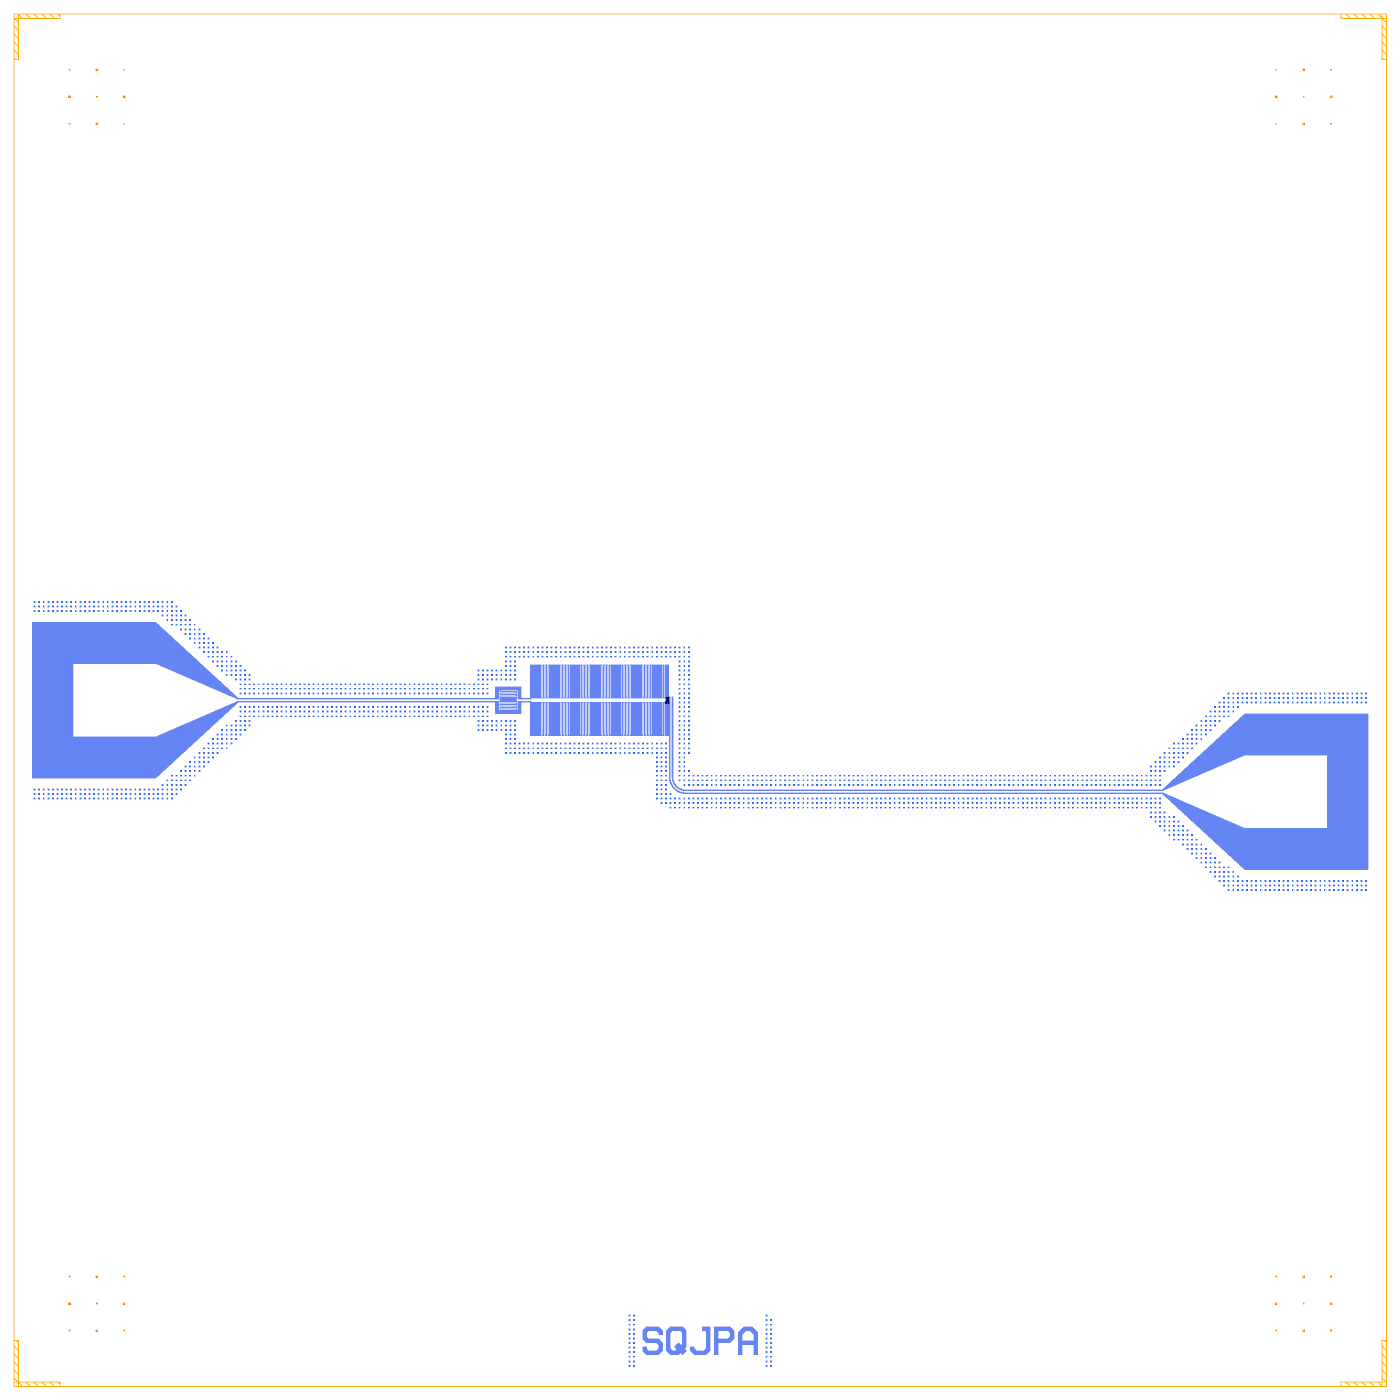

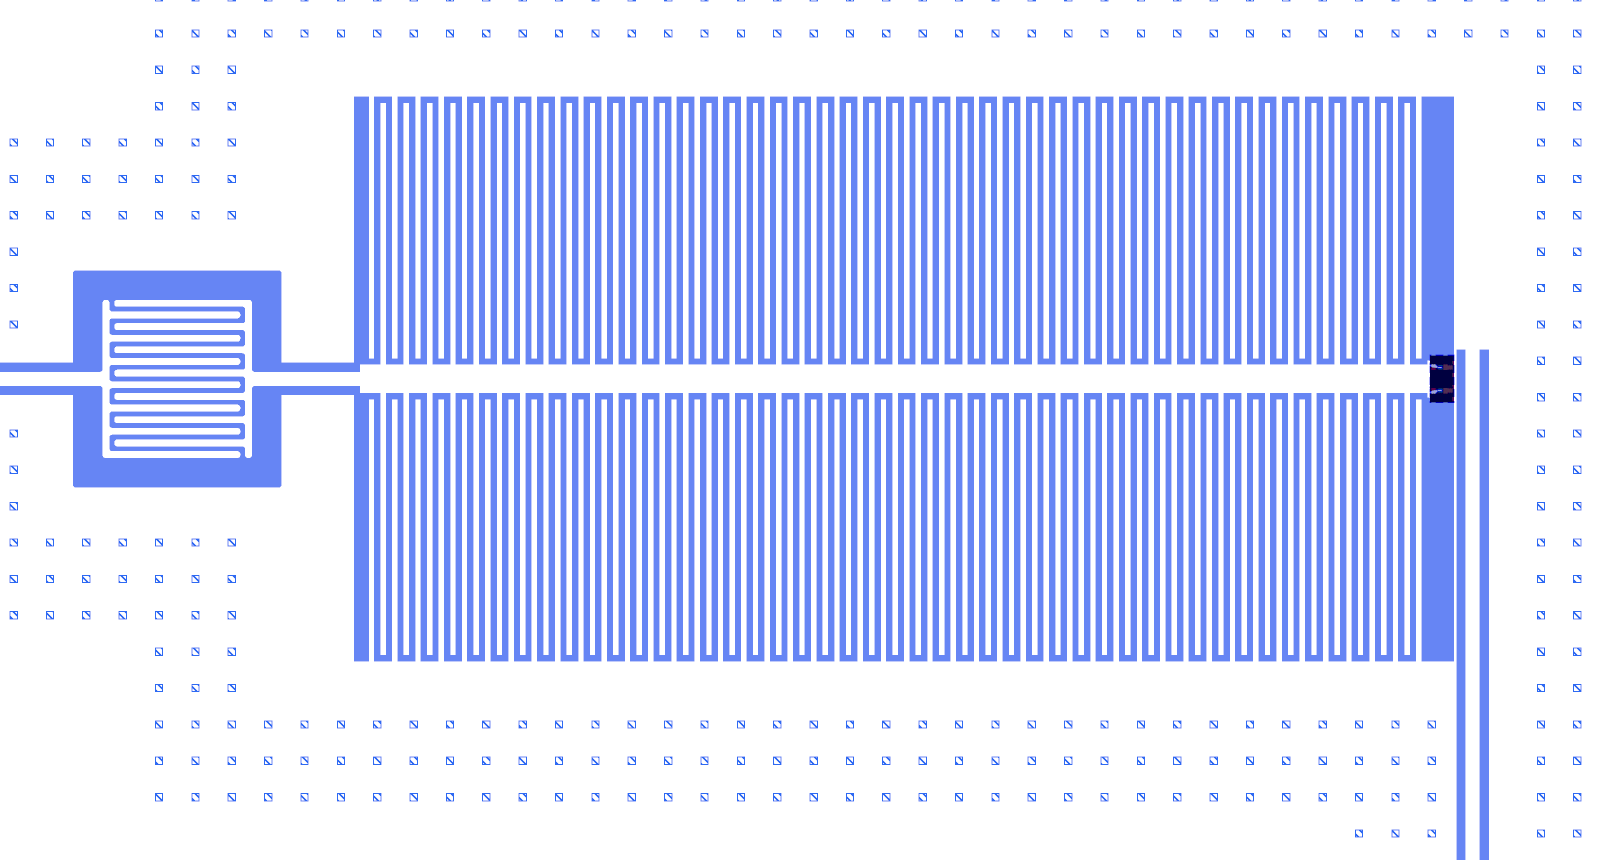

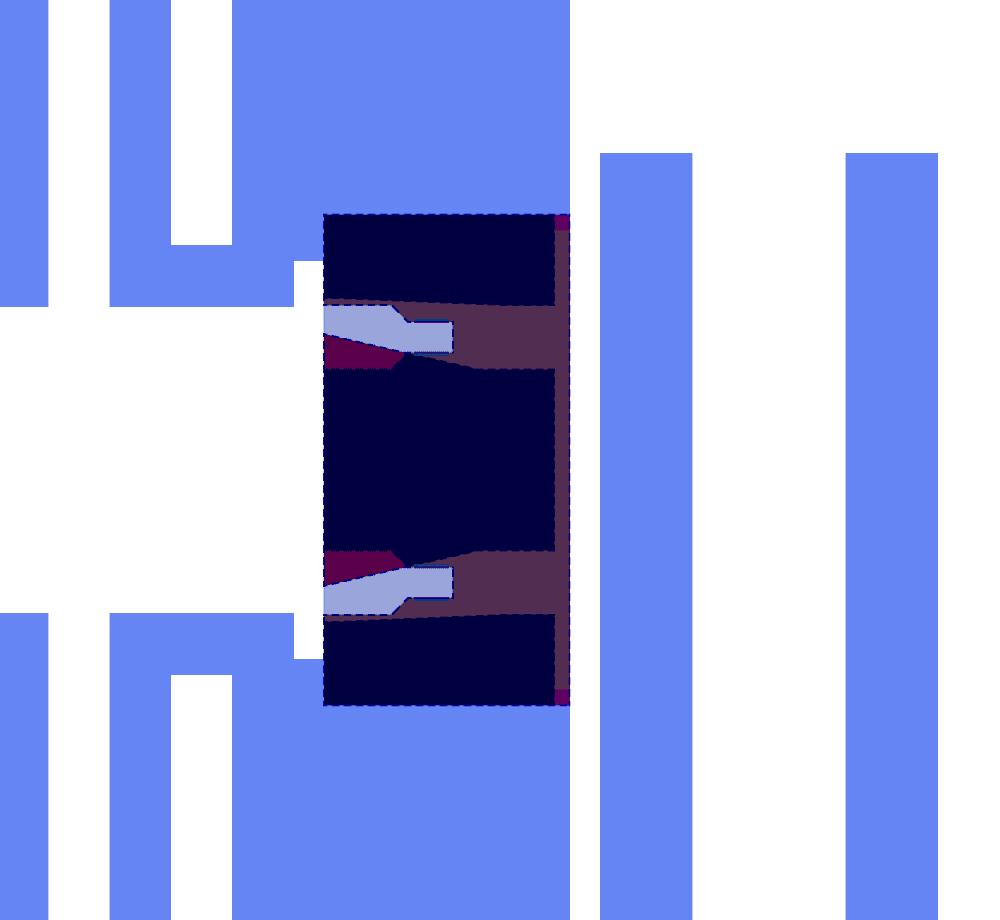

WindowsPath('examples/designs/amplifiers/twpa_sim_squid_jpa_squid.png')

In [16]:
show_snapshot(d, OUT / "twpa_sim_squid_jpa.png", size=(1400, 1400))
x, y = port_xy(d, "CC.a")
show_snapshot(d, OUT / "twpa_sim_squid_jpa_device.png", box=(x - 50, y - 330, x + 1050, y + 260), size=(1600, 860),
              width=640)
xs, ys = port_xy(d, "JS.flux")
show_snapshot(d, OUT / "twpa_sim_squid_jpa_squid.png", box=(xs - 50, YC - 30, xs + 15, YC + 30), size=(1000, 920),
              width=400)

## 14 · Summary
* **Matches the source:** a SQUID shunted by a capacitor, one-port reflection amplifier; here with the coupling and
  the flux / pump line drawn (twpa-sim leaves them external).
* **Differs:** the PDK trilayer SQUID (1.3 µA, L_s 0.25 nH) instead of twpa-sim's illustrative 40 µA; a planar
  IDC instead of MIM; f0 ≈ 7 GHz instead of ≈ 70 GHz.
* **PDK design warnings:** `pdk_rn` on `JS` (device R_n ≈ 1.7 kΩ).
* **Not modelled:** the flux line's mutual inductance (EM), SQUID loop inductance (β_L), pump depletion.